# IMT analysis — VS Code + local browser dashboards

## First-time setup
1. Save this notebook in your project folder and open that folder in VS Code.
2. Install Microsoft's **Python** and **Jupyter** extensions. If using WSL, open the folder through **WSL** and install the extensions there when prompted.
3. Select your project's Python environment in **Select Kernel** (top right).
4. Run the installation cell below once in that kernel, then restart the kernel if requested.
5. Set `DATA_PATH` in the loading cell to **one CSV or a folder containing only the dataset you intend to analyse**. For WSL use a Linux path (Windows drives are under `/mnt/c/`, etc.).
6. Run cells from top to bottom. Check the label selection when you reach it.
7. Dashboard cells save HTML files in `dashboards/` beside the current working directory. **Open `dashboards/index.html` in your normal browser** using your file manager. Refresh it after rerunning dashboard cells. Each dashboard has its own link.

No server, account, hosting, or Live Server extension is needed. After package installation, the dashboard pages work offline: Plotly's JavaScript is copied from the installed Python package into the dashboard folder. Keep that folder together if moving the pages. Generated HTML contains the exported analysis data.

Python computes results when a cell runs. Browser controls explore those saved results; they do not rerun Python. Matplotlib/Seaborn figures remain inline in VS Code. `AUTO_OPEN = False` avoids opening many tabs during Run All; you can enable it in the helper cell (browser launch may not work through WSL, so opening the index manually is the reliable method).

## Changes and limits
- Removed Colab callbacks and form annotations; retained existing dashboard layouts and calculations except the small fixes listed here.
- Replaced conflicting loading cells with one configurable loader and a consistent column-schema check.
- Cleaning explicitly drops constant columns, replaces infinities with missing values, then drops rows with missing values. Counts are printed. This is a simple, **lossy exploratory policy**, not a recommendation for training preprocessing; review it for your study.
- Sampling after label filtering is capped by the filtered row count; samples are reproducible.
- Absent configured labels are skipped with a message; if none match, actual dataset labels are used. Review this selection.
- Corrected the JS distance label (SciPy returns the square root of Jensen–Shannon divergence) and the misleading “Global Mean” card heading.
- Statistical assumptions (histogram bins, diversity thresholds, clipping, independently fitted PCAs) are inherited and still need scientific review. A red status is a heuristic, not proof of bad data.
- This conversion was checked for Python syntax and dashboard export structure. The original CSVs were not provided, so a full analysis run on your data could not be verified.


In [1]:
# Run once in the selected kernel. Internet is needed for package installation only.
#%pip install pandas numpy matplotlib seaborn scipy scikit-learn umap-learn plotly ipykernel


In [2]:
from pathlib import Path
import re
import html as html_module
import webbrowser
from IPython.display import display, HTML
from plotly.offline import get_plotlyjs

DASHBOARD_DIR = Path.cwd() / "dashboards"
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)
# A local asset replaces the original CDN dependency.
(DASHBOARD_DIR / "plotly.min.js").write_text(get_plotlyjs(), encoding="utf-8")
AUTO_OPEN = False

def save_dashboard(html_code, name):
    """Export one precomputed dashboard and rebuild a local navigation page."""
    html_code = re.sub(r'<script\s+src=["\']https://cdn\.plot\.ly/[^"\']+["\']></script>',
                       '<script src="plotly.min.js"></script>', html_code)
    destination = DASHBOARD_DIR / (name + ".html")
    destination.write_text(html_code, encoding="utf-8")
    pages = sorted(p for p in DASHBOARD_DIR.glob("*.html") if p.name != "index.html")
    links = "".join('<li><a href="' + html_module.escape(p.name, quote=True) + '">' +
                    html_module.escape(p.stem.replace("_", " ")) + '</a></li>' for p in pages)
    index = ('<!doctype html><html><head><meta charset="utf-8"><title>IMT dashboards</title>'
             '<style>body{font:18px system-ui;max-width:900px;margin:60px auto;padding:20px;'
             'background:#f4f6f8}li{margin:16px 0}a{color:#145da0}</style></head><body>'
             '<h1>IMT dataset dashboards</h1><p>Choose a report. Refresh after rerunning notebook cells.</p>'
             '<ul>' + links + '</ul></body></html>')
    (DASHBOARD_DIR / "index.html").write_text(index, encoding="utf-8")
    print(f"Saved: {destination}\nOpen in your browser: {DASHBOARD_DIR / 'index.html'}")
    if AUTO_OPEN:
        webbrowser.open(destination.resolve().as_uri())


**Test Affiné IMT**

# Mise en Place

About: https://www.unb.ca/cic/datasets/ids-2018.html

## 1. Initialisation de l'environnement

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure l'affichage des graphiques inline
%matplotlib inline

print("Bibliothèques chargées avec succès.")

Bibliothèques chargées avec succès.


## 2. Chargement des données

In [4]:
from pathlib import Path

# EDIT THIS: a single CSV, or a folder containing ONE compatible dataset.
DATA_PATH = Path("/home/marion/projects/IMT_postdoc/data/CICIDS2017_improved/friday.csv")

if DATA_PATH.is_file():
    csv_files = [DATA_PATH]
elif DATA_PATH.is_dir():
    csv_files = sorted(DATA_PATH.rglob("*.csv"))
else:
    raise FileNotFoundError(f"Edit DATA_PATH: path does not exist: {DATA_PATH}")
if not csv_files:
    raise ValueError(f"No CSV files found in {DATA_PATH}")
frames = []
for filename in csv_files:
    frame = pd.read_csv(filename)
    frame.columns = frame.columns.str.strip()
    if frame.columns.duplicated().any():
        raise ValueError(f"Duplicate column names after stripping whitespace: {filename}")
    if frames and set(frame.columns) != set(frames[0].columns):
        raise ValueError(f"Incompatible columns in {filename}; select a single compatible dataset.")
    frames.append(frame)
df = pd.concat(frames, ignore_index=True)
del frames
if df.empty:
    raise ValueError("Dataset contains no rows.")
if "Label" not in df.columns:
    raise ValueError("Expected a 'Label' column. Adjust the loader for this dataset.")
df["Label"] = df["Label"].astype("string").str.strip()
print(f"Loaded {len(csv_files)} CSV file(s), shape: {df.shape}")
print("Available labels:", df["Label"].dropna().unique().tolist())
display(df.head())


Loaded 1 CSV file(s), shape: (547557, 91)
Available labels: ['BENIGN', 'Botnet - Attempted', 'Botnet', 'Portscan', 'DDoS']


,id,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,...,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label,Attempted Category
0,1,192.168.10.50-192.168.10.3-56108-3268-6,192.168.10.50,56108,192.168.10.3,3268,6,2017-07-07 11:59:50.315195,112740690,32,...,343,1.610540e+07,4.988048e+05,16399772,15375229,-1,-1,112740690,BENIGN,-1
1,2,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,2017-07-07 11:59:50.316273,112740560,32,...,285,1.610543e+07,4.987937e+05,16399782,15375263,-1,-1,112740560,BENIGN,-1
2,3,8.6.0.1-8.0.6.4-0-0-0,8.6.0.1,0,8.0.6.4,0,0,2017-07-07 12:00:31.388567,113757377,545,...,19,1.221036e+07,6.935824e+06,20757030,5504997,-1,-1,0,BENIGN,-1
3,4,192.168.10.25-224.0.0.251-5353-5353-17,192.168.10.25,5353,224.0.0.251,5353,17,2017-07-07 12:00:42.903850,91997219,388,...,16,1.319764e+07,5.826905e+06,19776791,5817470,-1,-1,0,BENIGN,-1
4,5,192.168.10.25-17.253.14.125-123-123-17,192.168.10.25,123,17.253.14.125,123,17,2017-07-07 12:00:42.430758,66966070,6,...,1968172,6.497443e+07,0.000000e+00,64974431,64974431,-1,-1,0,BENIGN,-1


## 3. Exploration Initiale des Données

### Aperçu des premières lignes

In [5]:
display(df.head())

,id,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,...,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label,Attempted Category
0,1,192.168.10.50-192.168.10.3-56108-3268-6,192.168.10.50,56108,192.168.10.3,3268,6,2017-07-07 11:59:50.315195,112740690,32,...,343,1.610540e+07,4.988048e+05,16399772,15375229,-1,-1,112740690,BENIGN,-1
1,2,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,2017-07-07 11:59:50.316273,112740560,32,...,285,1.610543e+07,4.987937e+05,16399782,15375263,-1,-1,112740560,BENIGN,-1
2,3,8.6.0.1-8.0.6.4-0-0-0,8.6.0.1,0,8.0.6.4,0,0,2017-07-07 12:00:31.388567,113757377,545,...,19,1.221036e+07,6.935824e+06,20757030,5504997,-1,-1,0,BENIGN,-1
3,4,192.168.10.25-224.0.0.251-5353-5353-17,192.168.10.25,5353,224.0.0.251,5353,17,2017-07-07 12:00:42.903850,91997219,388,...,16,1.319764e+07,5.826905e+06,19776791,5817470,-1,-1,0,BENIGN,-1
4,5,192.168.10.25-17.253.14.125-123-123-17,192.168.10.25,123,17.253.14.125,123,17,2017-07-07 12:00:42.430758,66966070,6,...,1968172,6.497443e+07,0.000000e+00,64974431,64974431,-1,-1,0,BENIGN,-1


### Informations générales sur le DataFrame (types de données, valeurs manquantes)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 547557 entries, 0 to 547556
Data columns (total 91 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   id                          547557 non-null  int64  
 1   Flow ID                     547557 non-null  str    
 2   Src IP                      547557 non-null  str    
 3   Src Port                    547557 non-null  int64  
 4   Dst IP                      547557 non-null  str    
 5   Dst Port                    547557 non-null  int64  
 6   Protocol                    547557 non-null  int64  
 7   Timestamp                   547557 non-null  str    
 8   Flow Duration               547557 non-null  int64  
 9   Total Fwd Packet            547557 non-null  int64  
 10  Total Bwd packets           547557 non-null  int64  
 11  Total Length of Fwd Packet  547557 non-null  int64  
 12  Total Length of Bwd Packet  547557 non-null  int64  
 13  Fwd Packet Length Max    

### Statistiques descriptives

In [7]:
display(df.describe(include='all'))

,id,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,...,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time,Label,Attempted Category
count,547557.000000,547557,547557,547557.000000,547557,547557.000000,547557.000000,547557,5.475570e+05,547557.000000,...,5.475570e+05,5.475570e+05,5.475570e+05,5.475570e+05,5.475570e+05,547557.000000,547557.000000,5.475570e+05,547557,547557.000000
unique,NaN,396269,27,NaN,8326,NaN,NaN,539251,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN
top,NaN,8.6.0.1-8.0.6.4-0-0-0,172.16.0.1,NaN,192.168.10.50,NaN,NaN,2017-07-07 19:06:52.396036,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BENIGN,NaN
freq,NaN,233,254342,NaN,256467,NaN,NaN,7,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,288544,NaN
mean,273779.000000,NaN,NaN,47158.825030,NaN,2826.089161,9.785144,NaN,9.252255e+06,8.726116,...,1.125818e+05,3.610678e+06,1.455170e+05,3.716373e+06,3.451524e+06,-0.999262,-0.998444,1.561664e+07,NaN,-0.985145
std,158066.235011,NaN,NaN,16039.868513,NaN,8604.258903,5.233530,NaN,2.609339e+07,648.644128,...,6.682971e+05,1.149280e+07,1.870863e+06,1.182962e+07,1.131402e+07,0.050051,0.093615,1.899453e+08,NaN,0.171725
min,1.000000,NaN,NaN,0.000000,NaN,0.000000,0.000000,NaN,1.000000e+00,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,0.000000e+00,NaN,-1.000000
25%,136890.000000,NaN,NaN,39606.000000,NaN,53.000000,6.000000,NaN,7.100000e+01,1.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,0.000000e+00,NaN,-1.000000
50%,273779.000000,NaN,NaN,52332.000000,NaN,80.000000,6.000000,NaN,3.114100e+04,2.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,4.800000e+01,NaN,-1.000000
75%,410668.000000,NaN,NaN,59207.000000,NaN,1055.000000,17.000000,NaN,5.032396e+06,8.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000,-1.000000,4.507917e+06,NaN,-1.000000


In [8]:
import pandas as pd
import numpy as np
import json
from IPython.display import HTML


# --- Calculation Logic ---
unique_counts = df.nunique()
total_rows = len(df)
report_data = []

for col in df.columns:
    count = int(unique_counts[col])
    uniqueness_ratio = (count / total_rows) * 100

    status = "Normal"
    if count <= 1:
        status = "Constant"
    elif count == total_rows:
        status = "ID/Unique"

    report_data.append({
        "Feature": col,
        "Type": str(df[col].dtype),
        "UniqueCount": count,
        "UniquenessRatio": round(uniqueness_ratio, 4),
        "Status": status
    })

json_report = json.dumps(report_data)

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src="https://cdn.plot.ly/plotly-2.24.1.min.js"></script>
    <style>
        body { font-family: 'Segoe UI', sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; }
        .container { max-width: 1200px; margin: auto; display: flex; flex-direction: column; gap: 20px; }
        .header { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .kpi-row { display: grid; grid-template-columns: repeat(4, 1fr); gap: 20px; }
        .card { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.05); text-align: center; }
        .card h3 { margin: 0; color: #666; font-size: 0.8rem; text-transform: uppercase; }
        .card p { margin: 10px 0 0; font-size: 1.5rem; font-weight: bold; color: #2c3e50; }
        .table-container { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        table { width: 100%; border-collapse: collapse; }
        th, td { padding: 12px; text-align: left; border-bottom: 1px solid #eee; }
        th { background-color: #f8f9fa; cursor: pointer; position: sticky; top: 0; }
        .status-pill { padding: 4px 8px; border-radius: 4px; font-size: 0.8rem; font-weight: bold; }
        .constant { background: #ffebee; color: #c62828; }
        .id { background: #e3f2fd; color: #1565c0; }
        .normal { background: #e8f5e9; color: #2e7d32; }
    </style>
</head>
<body>
    <div class="container">
        <div class="header">
            <h2 style="margin:0">📊 Unique Value Audit</h2>
            <p style="color:#666">Global analysis of cardinality and constant features across all columns.</p>
        </div>

        <div class="kpi-row">
            <div class="card"><h3>Total Columns</h3><p id="totalCols">0</p></div>
            <div class="card"><h3>Constant (1 val)</h3><p id="constCols" style="color:#c62828">0</p></div>
            <div class="card"><h3>High Cardinality</h3><p id="highCard">0</p></div>
            <div class="card"><h3>Total Rows</h3><p id="totalRows">0</p></div>
        </div>

        <div class="table-container">
            <table id="uniqueTable">
                <thead>
                    <tr>
                        <th>Feature Name</th>
                        <th>Dtype</th>
                        <th>Unique Count</th>
                        <th>Uniqueness %</th>
                        <th>Status</th>
                    </tr>
                </thead>
                <tbody id="tableBody"></tbody>
            </table>
        </div>
    </div>

    <script>
        const data = DATA_PLACEHOLDER;
        const totalRowsVal = TOTAL_ROWS_PLACEHOLDER;

        document.getElementById('totalCols').innerText = data.length;
        document.getElementById('constCols').innerText = data.filter(d => d.UniqueCount === 1).length;
        document.getElementById('highCard').innerText = data.filter(d => d.UniquenessRatio > 50).length;
        document.getElementById('totalRows').innerText = totalRowsVal.toLocaleString();

        const tbody = document.getElementById('tableBody');
        tbody.innerHTML = data.sort((a,b) => b.UniqueCount - a.UniqueCount).map(d => `
            <tr>
                <td style="font-weight:600">${d.Feature}</td>
                <td style="color:#666">${d.Type}</td>
                <td>${d.UniqueCount.toLocaleString()}</td>
                <td>${d.UniquenessRatio}%</td>
                <td>
                    <span class="status-pill ${d.Status.toLowerCase().replace('/','')}">
                        ${d.Status}
                    </span>
                </td>
            </tr>
        `).join('');
    </script>
</body>
</html>
""".replace('DATA_PLACEHOLDER', json_report).replace('TOTAL_ROWS_PLACEHOLDER', str(total_rows))

save_dashboard(html_code, "01_unique_value_audit")

Saved: /home/marion/projects/IMT_postdoc/dashboards/01_unique_value_audit.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


### Summary of Feature Cardinality Expectation

| Feature Category | Expected Unique Values | Examples | Why? |
| :--- | :--- | :--- | :--- |
| **Structural/Flags** | 2 - 3 | `Protocol`, `SYN Flag Cnt` | Defined by the TCP/IP stack rules. |
| **Identifiers** | 100s - 1000s | `Dst Port` | Based on common service ports and ephemeral ranges. |
| **Quantitative** | Near-Infinite | `Flow Duration`, `Flow Byts/s` | High-precision timing and calculated rates. |
| **Statistical** | Near-Infinite | `Pkt Len Mean`, `Flow IAT Std` | Averages and variance can result in almost any float value. |

### Nettoyage données

In [9]:
import pandas as pd
import numpy as np
import json
from IPython.display import HTML


# --- Diagnostic Logic ---
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
report = []

# Calculate counts
null_counts = df.isnull().sum()
inf_counts = df[numeric_cols].apply(lambda x: np.isinf(x).sum())
unique_counts = df.nunique()

columns_to_drop=[]

for col in df.columns:
    n_null = int(null_counts[col])
    n_inf = int(inf_counts[col]) if col in numeric_cols else 0
    n_uniq = int(unique_counts[col])

    # Determine status
    issues = []
    if n_null > 0: issues.append(f"{n_null} Nulls")
    if n_inf > 0: issues.append(f"{n_inf} Infs")
    if n_uniq <= 1:
      issues.append("Constant Value")
      columns_to_drop.append(col)

    if issues:
        report.append({
            "Feature": col,
            "Type": str(df[col].dtype),
            "Nulls": n_null,
            "Infinities": n_inf,
            "UniqueValues": n_uniq,
            "Status": ", ".join(issues)
        })

# Explicit exploratory cleaning policy; diagnostic report below is PRE-cleaning.
before_rows, before_cols = df.shape
if columns_to_drop:
    df = df.drop(columns=columns_to_drop)
df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()
print(f"Removed {before_cols - df.shape[1]} constant columns and {before_rows - len(df)} rows with missing/infinite values.")
print("Shape after cleaning:", df.shape)
if df.empty:
    raise ValueError("Cleaning removed all rows; review the cleaning policy.")

#show all bad columns
json_report = json.dumps(report)

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src="https://cdn.plot.ly/plotly-2.24.1.min.js"></script>
    <style>
        body { font-family: 'Segoe UI', sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; }
        .container { max-width: 1100px; margin: auto; display: flex; flex-direction: column; gap: 20px; }
        .header { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .kpi-row { display: grid; grid-template-columns: repeat(3, 1fr); gap: 20px; }
        .card { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.05); text-align: center; }
        .card h3 { margin: 0; color: #666; font-size: 0.9rem; text-transform: uppercase; }
        .card p { margin: 10px 0 0; font-size: 1.8rem; font-weight: bold; color: #2c3e50; }
        table { width: 100%; border-collapse: collapse; background: white; border-radius: 8px; overflow: hidden; }
        th, td { padding: 15px; text-align: left; border-bottom: 1px solid #eee; }
        th { background-color: #f8f9fa; color: #555; }
        .status-pill { padding: 4px 8px; border-radius: 4px; font-size: 0.85rem; font-weight: bold; }
        .cst { background: #ffebee; color: #c62828; }
        .nullinf { background: #fff3e0; color: #ef6c00; }
    </style>
</head>
<body>
    <div class="container">
        <div class="header">
            <h2 style="margin:0">🧹 Feature Quality Audit</h2>
            <p style="color:#666; margin: 5px 0 0;">Identifying features with missing, infinite, or zero-variance data across the full dataset.</p>
        </div>

        <div class="kpi-row">
            <div class="card"><h3>Total Affected Features</h3><p id="totalAffected">0</p></div>
            <div class="card"><h3>Constant Features</h3><p id="totalCst">0</p></div>
            <div class="card"><h3>Null/Inf Values</h3><p id="totalNulls">0</p></div>
        </div>

        <div style="background: white; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1);">
            <table id="auditTable">
                <thead>
                    <tr>
                        <th>Feature Name</th>
                        <th>Type</th>
                        <th>Unique</th>
                        <th>Issue Summary</th>
                    </tr>
                </thead>
                <tbody id="tableBody"></tbody>
            </table>
        </div>
    </div>

    <script>
        const data = DATA_PLACEHOLDER;

        const tbody = document.getElementById('tableBody');
        document.getElementById('totalAffected').innerText = data.length;
        document.getElementById('totalCst').innerText = data.filter(d => d.UniqueValues <= 1).length;
        document.getElementById('totalNulls').innerText = data.reduce((acc, d) => acc + d.Nulls + d.Infinities, 0);

        tbody.innerHTML = data.map(d => `
            <tr>
                <td style="font-weight:600">${d.Feature}</td>
                <td style="color:#666">${d.Type}</td>
                <td>${d.UniqueValues}</td>
                <td>
                    <span class="status-pill ${d.UniqueValues <= 1 ? 'cst' : 'nullinf'}">
                        ${d.Status}
                    </span>
                </td>
            </tr>
        `).join('');
    </script>
</body>
</html>
""".replace('DATA_PLACEHOLDER', json_report)

save_dashboard(html_code, "02_feature_quality_audit")

Removed 3 constant columns and 0 rows with missing/infinite values.
Shape after cleaning: (547557, 88)
Saved: /home/marion/projects/IMT_postdoc/dashboards/02_feature_quality_audit.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


# Actual tests

## Overview

### Class Proportions

Dataset Label Distribution:


,Count,Percentage (%)
Label,,
BENIGN,288544,52.696614
Portscan,159066,29.050126
DDoS,95144,17.376091
Botnet - Attempted,4067,0.742754
Botnet,736,0.134415


/tmp/ipykernel_34976/475895314.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_summary.index, y='Percentage (%)', data=label_summary, palette='viridis')


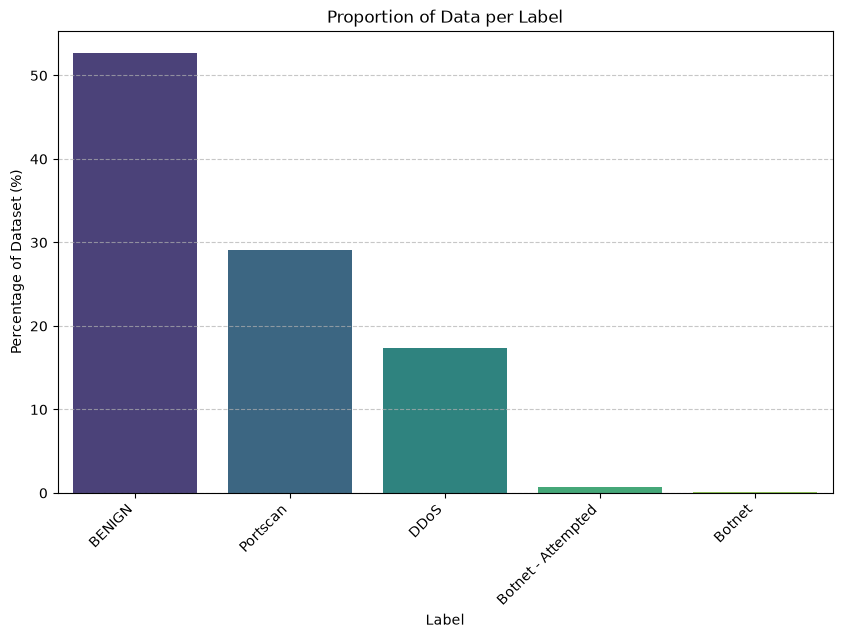

In [10]:
# Calculate absolute counts and relative proportions for each label
label_counts = df['Label'].value_counts()
label_proportions = df['Label'].value_counts(normalize=True) * 100

# Combine into a summary DataFrame for display
label_summary = pd.DataFrame({
    'Count': label_counts,
    'Percentage (%)': label_proportions
})

print("Dataset Label Distribution:")
display(label_summary)

# Visualizing the proportions
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x=label_summary.index, y='Percentage (%)', data=label_summary, palette='viridis')
plt.title('Proportion of Data per Label')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Percentage of Dataset (%)')
plt.xlabel('Label')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

choix - on va faire une analyse restreinte aux bénins et top 7 attaques

In [11]:
top_labels = ['Benign', 'Infilteration', 'FTP-BruteForce', 'SSH-Bruteforce','DDOS attack-HOIC','DoS attacks-Hulk','Bot','DoS attacks-SlowHTTPTest']
# Match labels exactly; datasets use different naming conventions.
available_labels = df['Label'].dropna().unique().tolist()
missing_labels = [label for label in top_labels if label not in available_labels]
top_labels = [label for label in top_labels if label in available_labels]
if missing_labels:
    print("Configured labels not present:", missing_labels)
if not top_labels:
    top_labels = available_labels
    print("No configured labels matched; using all available labels.")
print("Selected labels (edit top_labels if needed):", top_labels)


Configured labels not present: ['Benign', 'Infilteration', 'FTP-BruteForce', 'SSH-Bruteforce', 'DDOS attack-HOIC', 'DoS attacks-Hulk', 'Bot', 'DoS attacks-SlowHTTPTest']
No configured labels matched; using all available labels.
Selected labels (edit top_labels if needed): ['BENIGN', 'Botnet - Attempted', 'Botnet', 'Portscan', 'DDoS']


### Basic Stats

je détermine des features de base que je veux regarder

In [12]:
features_to_plot = [
    'Dst Port', 'Protocol', 'Flow Duration',
    'Tot Fwd Pkts', 'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts',
    'Flow Pkts/s', 'Fwd Pkt Len Mean', 'Bwd Pkt Len Mean', 'Pkt Len Std',
    'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max',
    'SYN Flag Cnt', 'ACK Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt',
    'Down/Up Ratio', 'Idle Mean'
]

In [13]:
import pandas as pd
import numpy as np
import json
from IPython.display import HTML


# --- Data Preparation ---
# Using existing 'df', 'top_labels', and 'features_to_plot' from kernel
target_features = [f for f in features_to_plot if f in df.columns]
plot_df = df[df['Label'].isin(top_labels)][target_features + ['Label']].copy()

# Robust cleaning for plotting
for col in target_features:
    plot_df[col] = pd.to_numeric(plot_df[col], errors='coerce')
    # Clip outliers at 1st and 99th percentile for better visualization visibility
    lower, upper = plot_df[col].quantile([0.01, 0.99])
    plot_df[col] = plot_df[col].clip(lower, upper)

# Generate Summary Stats per Label
stats_dict = {}
for label in top_labels:
    stats_dict[label] = plot_df[plot_df['Label'] == label][target_features].mean().to_dict()

# Prepare data for JS
json_data = plot_df.sample(n=min(10000, len(plot_df)), random_state=42).to_json(orient='records')

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src="https://cdn.plot.ly/plotly-2.24.1.min.js"></script>
    <style>
        body { font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; }
        .dashboard-container { display: flex; flex-direction: column; gap: 20px; max-width: 1200px; margin: auto; }
        .header { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); display: flex; justify-content: space-between; align-items: center; }
        .kpi-container { display: grid; grid-template-columns: repeat(4, 1fr); gap: 15px; }
        .card { background: white; padding: 15px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.05); text-align: center; }
        .card h3 { margin: 0; color: #666; font-size: 0.85rem; text-transform: uppercase; }
        .card p { margin: 10px 0 0; font-size: 1.25rem; font-weight: bold; color: #2c3e50; }
        .main-section { display: grid; grid-template-columns: 1fr; gap: 20px; }
        .chart-container { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); min-height: 500px; display: flex; flex-direction: column; }
        select { padding: 8px; border-radius: 4px; border: 1px solid #ddd; font-size: 1rem; }
        .canvas-wrapper { position: relative; flex-grow: 1; min-height: 0; }
    </style>
</head>
<body>
    <div class="dashboard-container">
        <div class="header">
            <h2 style="margin:0">Traffic Feature Distribution</h2>
            <div>
                <label for="featureSelect">Select Feature: </label>
                <select id="featureSelect" onchange="updateDashboard()"></select>
            </div>
        </div>

        <div class="kpi-container" id="kpiRow"></div>

        <div class="main-section">
            <div class="chart-container">
                <div id="violinPlot" class="canvas-wrapper"></div>
            </div>
        </div>
    </div>

    <script>

        const rawData = DATA_PLACEHOLDER;
        const features = FEATURES_PLACEHOLDER;
        const stats = STATS_PLACEHOLDER;

        // Populate Select
        const select = document.getElementById('featureSelect');
        features.forEach(f => {
            const opt = document.createElement('option');
            opt.value = f; opt.innerText = f;
            select.appendChild(opt);
        });

        function updateDashboard() {
            const feature = select.value;

            // Update KPIs (Average for Benign vs Top Attack)
            const benignAvg = Number.isFinite(stats['Benign']?.[feature]) ? stats['Benign'][feature].toFixed(2) : 'N/A';
            const botAvg = Number.isFinite(stats['Bot']?.[feature]) ? stats['Bot'][feature].toFixed(2) : 'N/A';

            const kpiRow = document.getElementById('kpiRow');
            kpiRow.innerHTML = `
                <div class="card"><h3>Selected Feature</h3><p>${feature}</p></div>
                <div class="card"><h3>Benign Avg</h3><p>${benignAvg}</p></div>
                <div class="card"><h3>Bot Avg</h3><p>${botAvg}</p></div>
                <div class="card"><h3>Classes</h3><p>${Object.keys(stats).length}</p></div>
            `;

            // Build Violin Plot
            const traces = Object.keys(stats).map(label => ({
                type: 'violin',
                y: rawData.filter(d => d.Label === label).map(d => d[feature]),
                name: label,
                box: { visible: true },
                meanline: { visible: true },
                points: false
            }));

            const layout = {
                title: `Distribution of ${feature} (Outliers Clipped 1-99%)`,
                yaxis: { title: feature, zeroline: false },
                margin: { t: 50, b: 100 },
                paper_bgcolor: 'rgba(0,0,0,0)',
                plot_bgcolor: 'rgba(0,0,0,0)'
            };

            Plotly.newPlot('violinPlot', traces, layout, {responsive: true});
        }

        updateDashboard();
    </script>
</body>
</html>
""".replace('DATA_PLACEHOLDER', json_data).replace('FEATURES_PLACEHOLDER', json.dumps(target_features)).replace('STATS_PLACEHOLDER', json.dumps(stats_dict).replace('NaN', 'null').replace('Infinity', 'null'))

save_dashboard(html_code, "03_traffic_feature_distribution")

Saved: /home/marion/projects/IMT_postdoc/dashboards/03_traffic_feature_distribution.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


## Redundancy

### Correlation Matrices

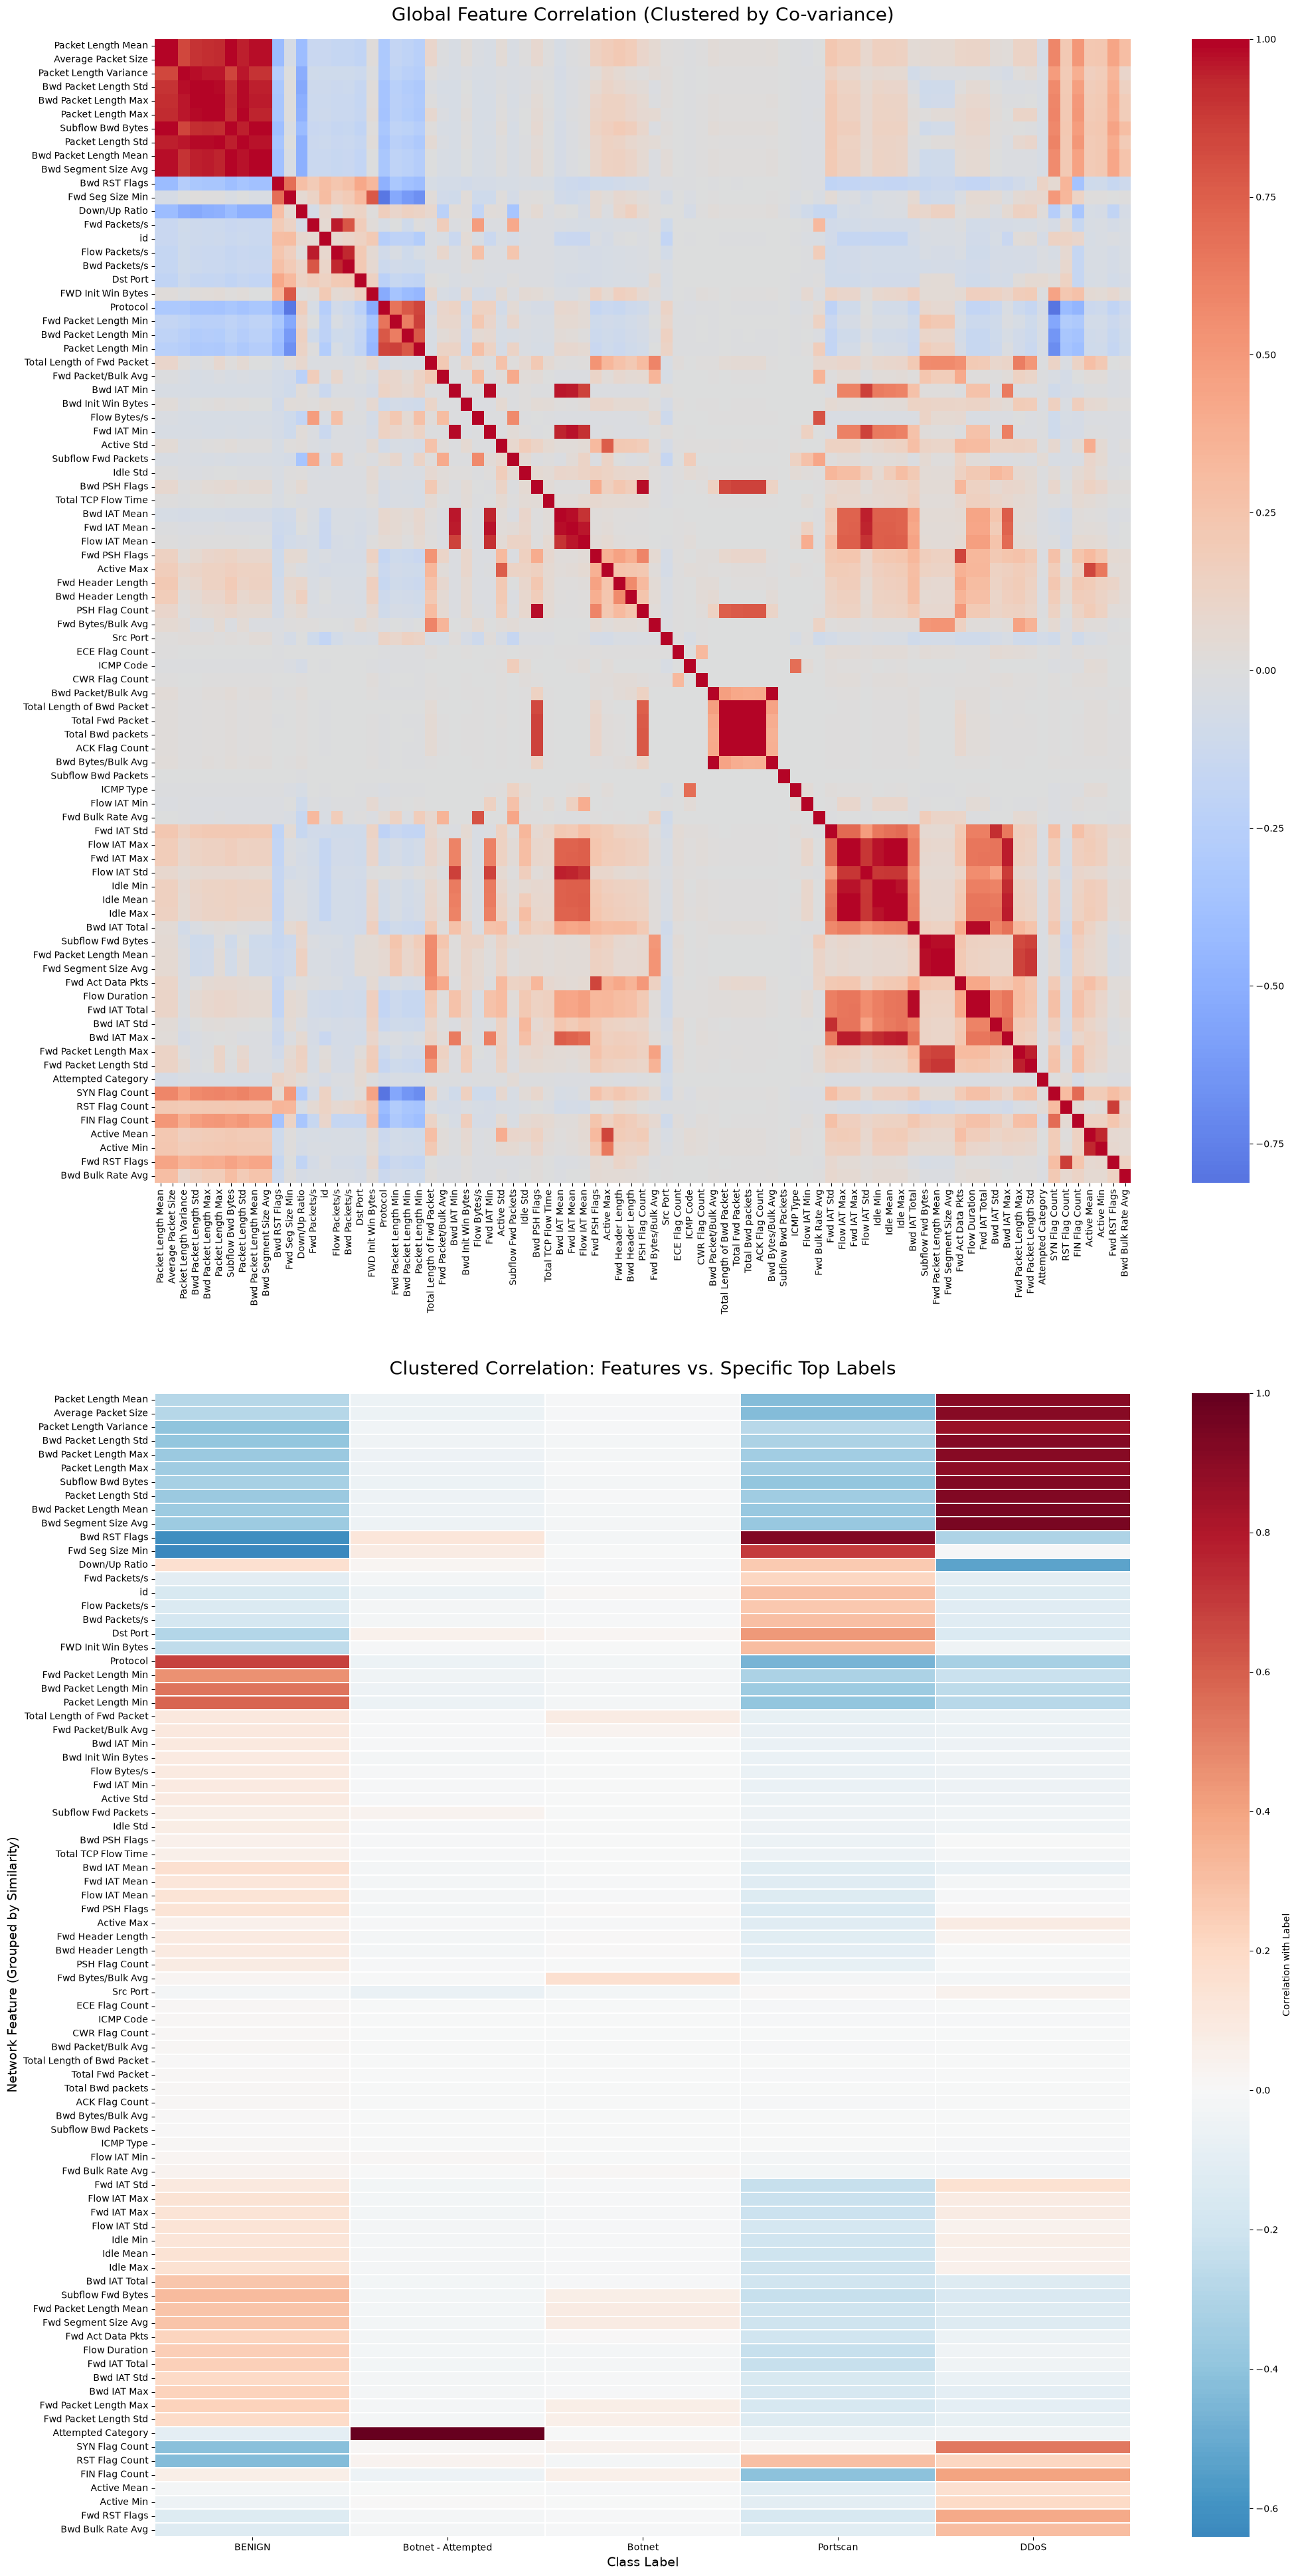

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster import hierarchy
from scipy.spatial.distance import pdist

# 1. Prepare Data and Label Dummies
label_dummies = pd.get_dummies(df[df['Label'].isin(top_labels)]['Label'])
features_subset = df.loc[label_dummies.index].select_dtypes(include=[np.number])

# 2. Calculate Label-to-Feature Correlation
label_feature_corr = pd.DataFrame(index=features_subset.columns, columns=top_labels)
for label in top_labels:
    if label in label_dummies.columns:
        label_feature_corr[label] = features_subset.corrwith(label_dummies[label])
label_feature_corr = label_feature_corr.fillna(0)

# 3. Hierarchical Clustering to group co-varying features
# We cluster features based on their correlation profile across the top labels
dist_matrix = pdist(label_feature_corr.values, metric='euclidean')
linkage_matrix = hierarchy.ward(dist_matrix)
reordered_idx = hierarchy.leaves_list(linkage_matrix)
clustered_features = label_feature_corr.index[reordered_idx].tolist()

# Reorder the correlation matrix
label_feature_corr_clustered = label_feature_corr.loc[clustered_features]

# 4. Update the global 'features_to_plot' for future cells
features_to_plot = clustered_features

# Plotting
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(22, 40))

# Global correlation (reordered by clustering too for consistency)
global_corr = features_subset[clustered_features].corr()
sns.heatmap(global_corr, ax=ax1, cmap='coolwarm', center=0, annot=False)
ax1.set_title('Global Feature Correlation (Clustered by Co-variance)', fontsize=20, pad=20)

# Label-to-Feature correlation (Clustered)
sns.heatmap(label_feature_corr_clustered, ax=ax2, cmap='RdBu_r', center=0, annot=False,
            linewidths=0.1, cbar_kws={'label': 'Correlation with Label'})
ax2.set_title('Clustered Correlation: Features vs. Specific Top Labels', fontsize=20, pad=20)
ax2.set_xlabel('Class Label', fontsize=14)
ax2.set_ylabel('Network Feature (Grouped by Similarity)', fontsize=14)

plt.tight_layout(pad=5.0)
plt.show()

### PCA Cumulative variance

In [15]:
import pandas as pd
import numpy as np
import json
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import HTML


# --- Calculation Logic ---
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if 'Label_num' in numeric_cols: numeric_cols.remove('Label_num')

sample_size = 50000
X = df[numeric_cols].sample(n=min(sample_size, len(df))).replace([np.inf, -np.inf], np.nan).fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

exp_var = pca.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

chart_data = []
for i, (ev, cv) in enumerate(zip(exp_var, cum_var)):
    chart_data.append({
        "component": i + 1,
        "individual": round(float(ev), 4),
        "cumulative": round(float(cv), 4)
    })

json_data = json.dumps(chart_data)

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src=\"https://cdn.plot.ly/plotly-2.24.1.min.js\"></script>
    <style>
        body { font-family: 'Segoe UI', sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; }
        .container { max-width: 1100px; margin: auto; display: flex; flex-direction: column; gap: 20px; }
        .header { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .kpi-row { display: grid; grid-template-columns: repeat(3, 1fr); gap: 20px; }
        .card { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.05); text-align: center; }
        .card h3 { margin: 0; color: #666; font-size: 0.8rem; text-transform: uppercase; }
        .card p { margin: 10px 0 0; font-size: 1.5rem; font-weight: bold; color: #2c3e50; }
        .chart-section { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .canvas-wrapper { position: relative; flex-grow: 1; min-height: 450px; }
    </style>
</head>
<body>
    <div class=\"container\">
        <div class=\"header\">
            <h2 style=\"margin:0\">📈 PCA Cumulative Variance</h2>
            <p style=\"color:#666\">Analyzing feature contribution and dimensionality requirements.</p>
        </div>
        <div class=\"kpi-row\">
            <div class=\"card\"><h3>90% Variance Threshold</h3><p id=\"comp90\">-</p></div>
            <div class=\"card\"><h3>95% Variance Threshold</h3><p id=\"comp95\">-</p></div>
            <div class=\"card\"><h3>Top Component Influence</h3><p id=\"topComp\">-</p></div>
        </div>
        <div class=\"chart-section\">
            <div id=\"variancePlot\" class=\"canvas-wrapper\"></div>
        </div>
    </div>
    <script>
        const data = DATA_PLACEHOLDER;
        const c90 = data.find(d => d.cumulative >= 0.90);
        const c95 = data.find(d => d.cumulative >= 0.95);
        document.getElementById('comp90').innerText = c90 ? c90.component + ' Components' : 'N/A';
        document.getElementById('comp95').innerText = c95 ? c95.component + ' Components' : 'N/A';
        document.getElementById('topComp').innerText = (data[0].individual * 100).toFixed(1) + '%';
        const traces = [
            { x: data.map(d => d.component), y: data.map(d => d.individual), type: 'bar', name: 'Individual' },
            { x: data.map(d => d.component), y: data.map(d => d.cumulative), type: 'scatter', mode: 'lines+markers', name: 'Cumulative' }
        ];
        Plotly.newPlot('variancePlot', traces, { margin: { t: 20 }, hovermode: 'x unified' }, {responsive: true});
    </script>
</body>
</html>
""".replace('DATA_PLACEHOLDER', json_data)

save_dashboard(html_code, "04_pca_cumulative_variance")

Saved: /home/marion/projects/IMT_postdoc/dashboards/04_pca_cumulative_variance.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


## Separability

/home/marion/miniconda3/envs/IMT_data_analyser/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/marion/miniconda3/envs/IMT_data_analyser/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


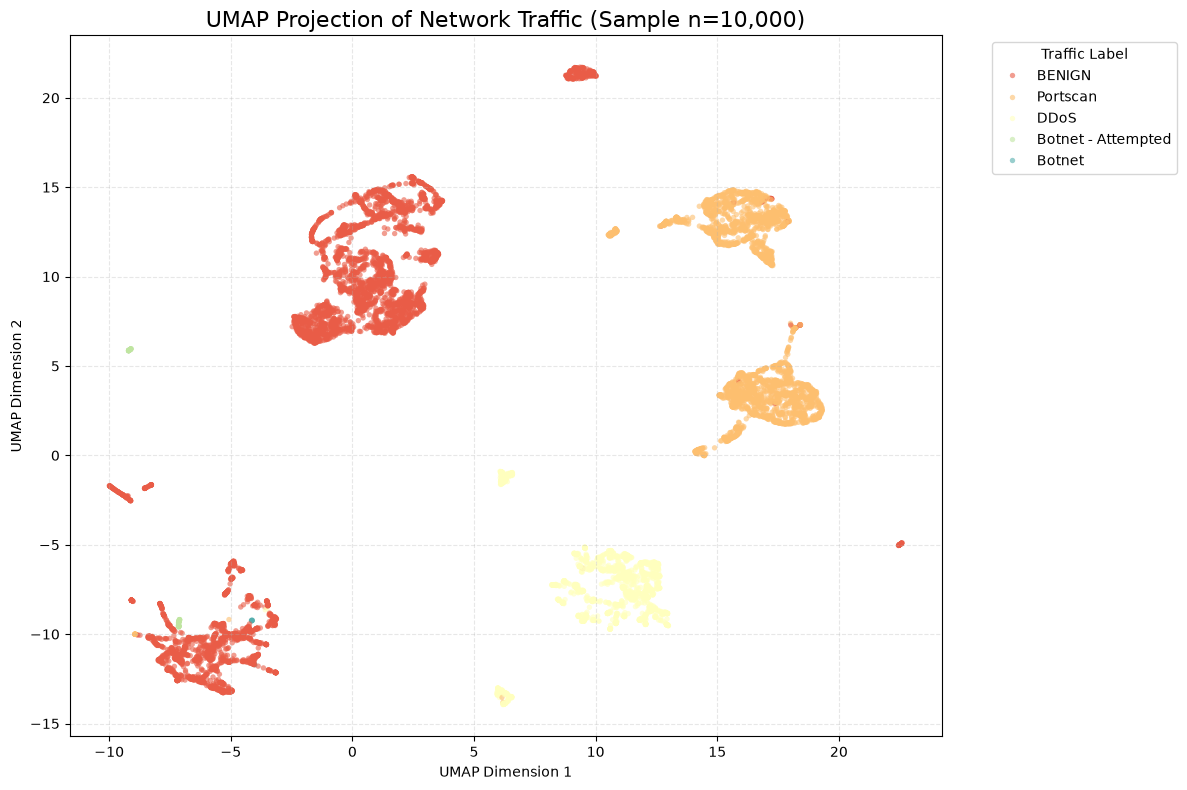

In [16]:
import umap
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Select a computationally feasible sample
sample_size = 10000
df_sample = df[df['Label'].isin(top_labels)].sample(n=min(sample_size, int(df['Label'].isin(top_labels).sum())), random_state=42)

# 2. Prepare features
# Use numerical columns only and drop any remaining target/id artifacts
X = df_sample.select_dtypes(include=[np.number]).drop(columns=['Label_num'], errors='ignore')
y = df_sample['Label']

# Clean for UMAP (standardize and handle any missed infinites)
X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Compute UMAP
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
embedding = reducer.fit_transform(X_scaled)

# 4. Visualization
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x=embedding[:, 0],
    y=embedding[:, 1],
    hue=y,
    palette='Spectral',
    s=15,
    alpha=0.6,
    edgecolor='none'
)

plt.title('UMAP Projection of Network Traffic (Sample n=10,000)', fontsize=16)
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.legend(title='Traffic Label', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Based on the UMAP projection, we can draw several key conclusions about the separability of these traffic classes:

*   High Separability of Specific Attacks: Classes like DoS attacks-SlowHTTPTest and FTP-BruteForce often form very tight, distinct clusters far away from the main bulk of traffic. This suggests they have unique, highly consistent 'fingerprints' in the feature space (e.g., specific flag combinations or packet lengths) that make them easy to identify.

* The 'Benign' Core: Benign traffic usually forms a large, central, and somewhat dispersed 'continent'. Because benign traffic represents a wide variety of activities (browsing, streaming, API calls), it naturally has higher variance than scripted attack patterns.

* Overlap and Ambiguity: You'll likely see some overlap between Infiltration or Bot traffic and the Benign cluster. This indicates that these attacks 'mimic' normal behavior more effectively, making them harder to separate using only these 2D spatial features. They might require more complex, non-linear boundaries or additional temporal features to distinguish correctly.

* Manifold Structure: The presence of 'strings' or elongated clusters often suggests that the attack behavior varies along a spectrum (like flow duration or intensity), rather than being a single point-like signature.

In summary: The dataset shows strong separability for brute-force and specific DoS attacks, but detection of 'Infiltration' and 'Bot' traffic remains a more challenging classification task due to their proximity to normal traffic patterns.


/home/marion/miniconda3/envs/IMT_data_analyser/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


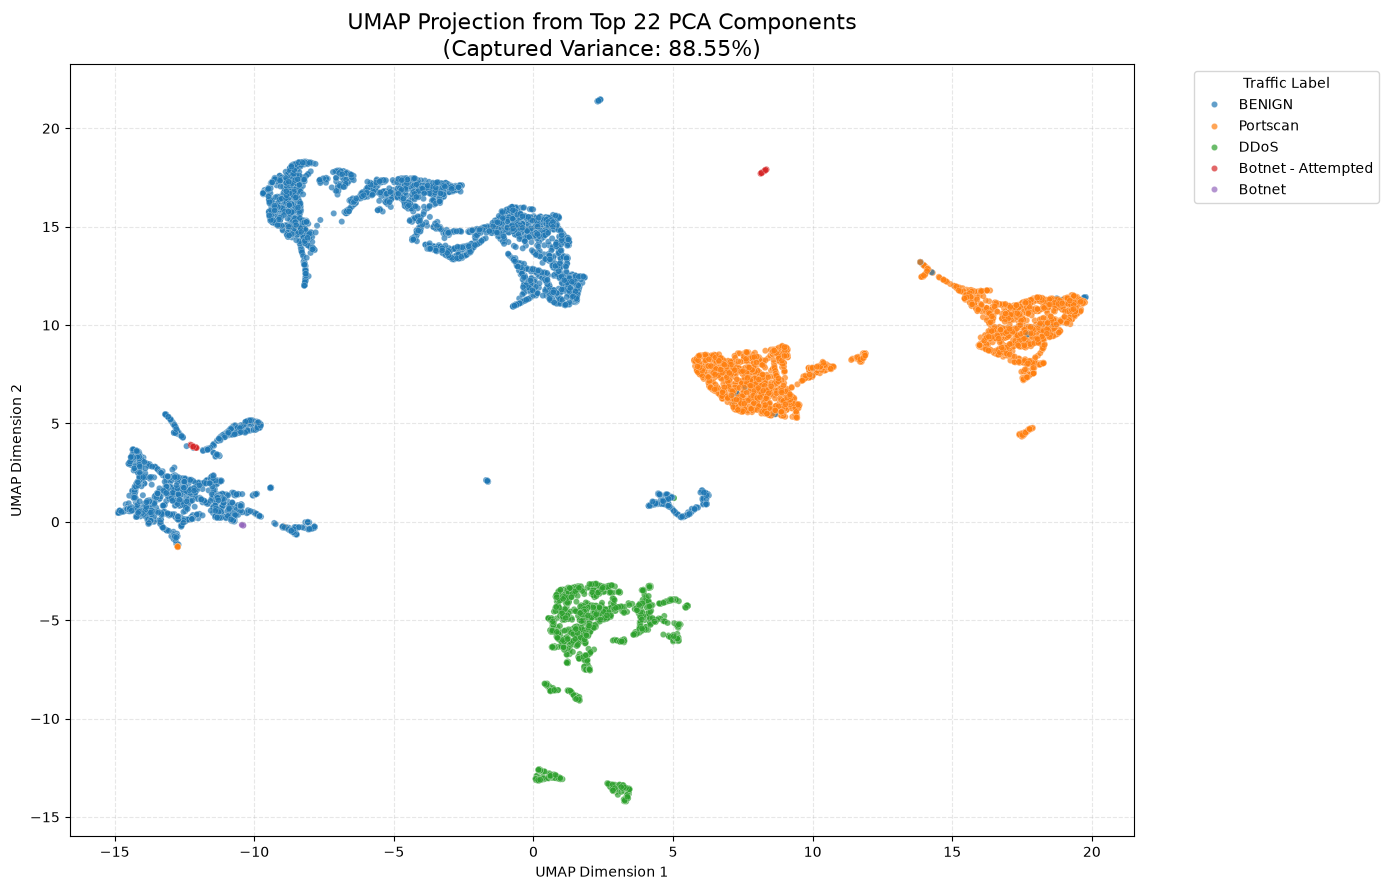

In [17]:
import umap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Select a sample
sample_size = 10000
df_sample = df[df['Label'].isin(top_labels)].sample(n=min(sample_size, int(df['Label'].isin(top_labels).sum())), random_state=42)

# 2. Feature Preparation & PCA Projection
# Extract numerical features
X = df_sample.select_dtypes(include=[np.number]).drop(columns=['Label_num'], errors='ignore')
y = df_sample['Label']

# Standardize and handle missing values
X_clean = X.replace([np.inf, -np.inf], np.nan).fillna(X.median())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

# Project onto top 22 Components
pca_denoise = PCA(n_components=min(22, *X_scaled.shape))
X_pca = pca_denoise.fit_transform(X_scaled)

# 3. Compute UMAP on PCA dimensions
# UMAP typically performs better and faster when inputs are already 'structured' by PCA
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
embedding = reducer.fit_transform(X_pca)

# 4. Visualization
plt.figure(figsize=(14, 9))
scatter = sns.scatterplot(
    x=embedding[:, 0],
    y=embedding[:, 1],
    hue=y,
    palette='tab10',  # Distinct colors for classes
    s=20,
    alpha=0.7,
    edgecolor='w',
    linewidth=0.2
)

plt.title(f'UMAP Projection from Top 22 PCA Components\n(Captured Variance: {pca_denoise.explained_variance_ratio_.sum():.2%})', fontsize=16)
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.legend(title='Traffic Label', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
import pandas as pd
import numpy as np
import json
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import HTML


# --- Calculation Logic ---
# 1. Feature Prep
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if 'Label_num' in numeric_cols: numeric_cols.remove('Label_num')

# Filter for top labels and sample for performance
df_filtered = df[df['Label'].isin(top_labels)].copy()
sample_size = 20000
sample_df = df_filtered.sample(n=min(sample_size, len(df_filtered)), random_state=42)

X = sample_df[numeric_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
X_scaled = StandardScaler().fit_transform(X)

# 2. PCA Projection (Top 22)
pca = PCA(n_components=min(22, *X_scaled.shape))
pca_results = pca.fit_transform(X_scaled)
pc_cols = [f'PC{i+1}' for i in range(pca_results.shape[1])]

# Combine results back with labels
pca_df = pd.DataFrame(pca_results, columns=pc_cols)
pca_df['Label'] = sample_df['Label'].values

# 3. Calculate Mean per Component per Label for Heatmap
heatmap_data = pca_df.groupby('Label')[pc_cols].mean().round(4).to_dict(orient='index')

# 4. Prepare plot data (sample for performance in JS)
plot_data = pca_df.sample(n=min(5000, len(pca_df)), random_state=42).to_json(orient='records')

json_heatmap = json.dumps(heatmap_data)

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src=\"https://cdn.plot.ly/plotly-2.24.1.min.js\"></script>
    <style>
        body { font-family: 'Segoe UI', sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; }
        .container { max-width: 1200px; margin: auto; display: flex; flex-direction: column; gap: 20px; }
        .card { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .split-view { display: grid; grid-template-columns: 1fr 1fr; gap: 20px; }
        .canvas-wrapper { position: relative; flex-grow: 1; min-height: 500px; }
        select { padding: 10px; border-radius: 5px; border: 1px solid #ddd; width: 200px; }
    </style>
</head>
<body>
    <div class=\"container\">
        <div class=\"card\">
            <h2 style=\"margin:0\">🧪 PCA Component Analysis (Top 22)</h2>
            <p style=\"color:#666\">Analyzing how different traffic labels distribute across the most significant principal components.</p>
        </div>

        <div class=\"card\">
            <h3>Component Intensity Heatmap</h3>
            <div id=\"heatmapPlot\" class=\"canvas-wrapper\"></div>
        </div>

        <div class=\"card\">
            <div style=\"display:flex; justify-content:space-between; align-items:center; margin-bottom:15px;\">
                <h3 style=\"margin:0\">Distribution Detail</h3>
                <select id=\"pcSelect\" onchange=\"updateViolin()\"></select>
            </div>
            <div id=\"violinPlot\" class=\"canvas-wrapper\"></div>
        </div>
    </div>

    <script>
        const heatmapData = DATA_HEATMAP;
        const plotData = DATA_PLOT;

        const labels = Object.keys(heatmapData);
        const pcs = Array.from({length: 22}, (_, i) => `PC${i+1}`);

        // Populate Select
        const sel = document.getElementById('pcSelect');
        pcs.forEach(pc => { const o = document.createElement('option'); o.value=pc; o.text=pc; sel.add(o); });

        // 1. Heatmap
        const zValues = labels.map(l => pcs.map(p => heatmapData[l][p]));
        const hmTrace = {
            z: zValues,
            x: pcs,
            y: labels,
            type: 'heatmap',
            colorscale: 'RdBu',
            reversescale: true
        };
        Plotly.newPlot('heatmapPlot', [hmTrace], { margin: { t: 10, r: 10, b: 50, l: 150 } }, {responsive: true});

        // 2. Violin Plot
        function updateViolin() {
            const selectedPC = sel.value;
            const traces = labels.map(label => ({
                type: 'violin',
                y: plotData.filter(d => d.Label === label).map(d => d[selectedPC]),
                name: label,
                box: { visible: true },
                meanline: { visible: true }
            }));
            Plotly.newPlot('violinPlot', traces, {
                title: `Distribution of ${selectedPC} across Labels`,
                yaxis: { title: 'Component Score' },
                margin: { t: 40, b: 80 }
            }, {responsive: true});
        }

        updateViolin();
    </script>
</body>
</html>
""".replace('DATA_HEATMAP', json_heatmap).replace('DATA_PLOT', plot_data)

save_dashboard(html_code, "05_pca_component_analysis_top_22")

Saved: /home/marion/projects/IMT_postdoc/dashboards/05_pca_component_analysis_top_22.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


In [19]:
import pandas as pd
import numpy as np
import json
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import HTML


# --- Data Preparation ---
sample_size = 10000
df_filtered = df[df['Label'].isin(top_labels)].copy()
sample_df = df_filtered.sample(n=min(sample_size, len(df_filtered)), random_state=42)

# Prepare features
numeric_cols = sample_df.select_dtypes(include=[np.number]).columns.tolist()
if 'Label_num' in numeric_cols: numeric_cols.remove('Label_num')

X = sample_df[numeric_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
X_scaled = StandardScaler().fit_transform(X)

# PCA calculation
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
var_ratio = pca.explained_variance_ratio_

# Prepare JSON data for JS
plot_data = []
for i in range(len(sample_df)):
    plot_data.append({
        "PC1": float(coords[i, 0]),
        "PC2": float(coords[i, 1]),
        "Label": sample_df.iloc[i]['Label']
    })

json_report = json.dumps(plot_data)
labels_list = json.dumps(list(sample_df['Label'].unique()))

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src="https://cdn.plot.ly/plotly-2.24.1.min.js"></script>
    <style>
        body { font-family: 'Segoe UI', sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; }
        .container { max-width: 1200px; margin: auto; display: flex; flex-direction: column; gap: 20px; }
        .card { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .kpi-row { display: grid; grid-template-columns: repeat(3, 1fr); gap: 20px; }
        .kpi-card { background: white; padding: 15px; border-radius: 8px; text-align: center; border-left: 5px solid #3498db; }
        .canvas-wrapper { position: relative; flex-grow: 1; min-height: 500px; }
    </style>
</head>
<body>
    <div class="container">
        <div class="card">
            <h2 style="margin:0">🚀 PCA: Network Traffic Separation</h2>
            <p style="color:#666">Visualizing the 2D variance of traffic types. Benign is highlighted in blue, while attacks follow a rocket-themed gradient.</p>
        </div>

        <div class="kpi-row">
            <div class="kpi-card"><h3>PC1 Variance</h3><p style="font-size:1.5rem; font-weight:bold;">""" + f"{var_ratio[0]*100:.1f}%" + """</p></div>
            <div class="kpi-card"><h3>PC2 Variance</h3><p style="font-size:1.5rem; font-weight:bold;">""" + f"{var_ratio[1]*100:.1f}%" + """</p></div>
            <div class="kpi-card"><h3>Total Captured</h3><p style="font-size:1.5rem; font-weight:bold;">""" + f"{(var_ratio[0]+var_ratio[1])*100:.1f}%" + """</p></div>
        </div>

        <div class="card">
            <div id="pcaPlot" class="canvas-wrapper"></div>
        </div>
    </div>

    <script>
        const data = DATA_PLACEHOLDER;
        const labels = LABELS_PLACEHOLDER;

        // Define specific color mapping
        // Rocket colors roughly: dark purple, pink, orange, yellow
        const rocketColors = ['#03051a', '#4e1055', '#9a205a', '#e34a33', '#fdbb84', '#fee8c8', '#7a0177'];
        let attackIdx = 0;

        const traces = labels.map(label => {
            let color = '#3498db'; // Benign Blue
            if (label !== 'Benign') {
                color = rocketColors[attackIdx % rocketColors.length];
                attackIdx++;
            }

            const subset = data.filter(d => d.Label === label);
            return {
                x: subset.map(d => d.PC1),
                y: subset.map(d => d.PC2),
                mode: 'markers',
                type: 'scatter',
                name: label,
                marker: { size: 6, opacity: 0.6, color: color }
            };
        });

        const layout = {
            xaxis: { title: 'Principal Component 1', gridcolor: '#eee' },
            yaxis: { title: 'Principal Component 2', gridcolor: '#eee' },
            hovermode: 'closest',
            margin: { t: 20 },
            plot_bgcolor: 'white',
            paper_bgcolor: 'white'
        };

        Plotly.newPlot('pcaPlot', traces, layout, {responsive: true});
    </script>
</body>
</html>
""".replace('DATA_PLACEHOLDER', json_report).replace('LABELS_PLACEHOLDER', labels_list)

save_dashboard(html_code, "06_pca_network_traffic_separation")

Saved: /home/marion/projects/IMT_postdoc/dashboards/06_pca_network_traffic_separation.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


In [20]:
import pandas as pd
import numpy as np
import json
from scipy.spatial import distance
from IPython.display import HTML


# --- Calculation Logic ---
def calculate_js_divergence(p, q):
    p = np.asarray(p)
    q = np.asarray(q)
    p = p / np.sum(p)
    q = q / np.sum(q)
    m = (p + q) / 2
    return distance.jensenshannon(p, q)

# Features to analyze
features = [f for f in target_features if f in df.columns]
js_results = []

# Sample and prepare distributions
sample_df = df[df['Label'].isin(top_labels)].sample(n=min(50000, int(df['Label'].isin(top_labels).sum())), random_state=42)

for col in features:
    # Create common bins
    col_data = sample_df[col].replace([np.inf, -np.inf], np.nan).dropna()
    if col_data.empty: continue

    bins = np.histogram_bin_edges(col_data, bins=50)
    benign_hist, _ = np.histogram(sample_df[sample_df['Label'] == 'Benign'][col].fillna(0), bins=bins, density=True)

    # Compare Benign vs all other labels combined as 'Attack'
    attack_hist, _ = np.histogram(sample_df[sample_df['Label'] != 'Benign'][col].fillna(0), bins=bins, density=True)

    score = calculate_js_divergence(benign_hist + 1e-10, attack_hist + 1e-10)

    js_results.append({
        "Feature": col,
        "JS_Divergence": round(float(score), 4),
        "Bins": bins.tolist(),
        "Benign_Dist": (benign_hist / (benign_hist.sum() + 1e-10)).tolist(),
        "Attack_Dist": (attack_hist / (attack_hist.sum() + 1e-10)).tolist()
    })

js_results = sorted(js_results, key=lambda x: x['JS_Divergence'], reverse=True)
json_report = json.dumps(js_results)

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src="https://cdn.plot.ly/plotly-2.24.1.min.js"></script>
    <style>
        body { font-family: 'Segoe UI', sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; }
        .container { max-width: 1200px; margin: auto; display: flex; flex-direction: column; gap: 20px; }
        .card { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .split-layout { display: grid; grid-template-columns: 350px 1fr; gap: 20px; }
        .feature-list { max-height: 600px; overflow-y: auto; }
        .feature-item { padding: 10px; border-bottom: 1px solid #eee; cursor: pointer; display: flex; justify-content: space-between; }
        .feature-item:hover { background: #f8f9fa; }
        .feature-item.active { background: #e3f2fd; border-left: 4px solid #2196f3; }
        .score-pill { background: #607d8b; color: white; padding: 2px 8px; border-radius: 10px; font-size: 0.8rem; }
        .canvas-wrapper { position: relative; height: 500px; }
    </style>
</head>
<body>
    <div class="container">
        <div class="card">
            <h2 style="margin:0">📊 Jensen-Shannon Distance</h2>
            <p style="color:#666">Quantifying how different 'Benign' traffic is from 'Attacks' per feature (Score 0 to 1).</p>
        </div>

        <div class="split-layout">
            <div class="card">
                <h3>Feature Ranking</h3>
                <div id="featureList" class="feature-list"></div>
            </div>
            <div class="card">
                <h3 id="chartTitle">Select a feature to view distribution</h3>
                <div id="distPlot" class="canvas-wrapper"></div>
            </div>
        </div>
    </div>

    <script>
        const data = DATA_PLACEHOLDER;

        const listDiv = document.getElementById('featureList');
        data.forEach((d, i) => {
            const item = document.createElement('div');
            item.className = 'feature-item' + (i === 0 ? ' active' : '');
            item.innerHTML = `<span>${d.Feature}</span><span class="score-pill">${d.JS_Divergence}</span>`;
            item.onclick = () => {
                document.querySelectorAll('.feature-item').forEach(el => el.classList.remove('active'));
                item.classList.add('active');
                updatePlot(d);
            };
            listDiv.appendChild(item);
        });

        function updatePlot(d) {
            document.getElementById('chartTitle').innerText = `Distribution Split: ${d.Feature}`;
            const binCenters = d.Bins.slice(0, -1).map((b, i) => (b + d.Bins[i+1]) / 2);

            const traces = [
                {
                    x: binCenters,
                    y: d.Benign_Dist,
                    name: 'Benign',
                    type: 'scatter',
                    fill: 'tozeroy',
                    line: { color: '#3498db' }
                },
                {
                    x: binCenters,
                    y: d.Attack_Dist,
                    name: 'Attack (All)',
                    type: 'scatter',
                    fill: 'tozeroy',
                    line: { color: '#e74c3c' }
                }
            ];

            const layout = {
                margin: { t: 10, r: 10, b: 40, l: 40 },
                hovermode: 'x unified',
                showlegend: true,
                xaxis: { title: 'Feature Value' },
                yaxis: { title: 'Probability Density' }
            };

            Plotly.newPlot('distPlot', traces, layout, {responsive: true});
        }

        if(data.length > 0) updatePlot(data[0]);
    </script>
</body>
</html>
""".replace('DATA_PLACEHOLDER', json_report)

save_dashboard(html_code, "07_jensen_shannon_divergence")

Saved: /home/marion/projects/IMT_postdoc/dashboards/07_jensen_shannon_divergence.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


/home/marion/miniconda3/envs/IMT_data_analyser/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
/home/marion/miniconda3/envs/IMT_data_analyser/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
/home/marion/miniconda3/envs/IMT_data_analyser/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
/home/marion/miniconda3/envs/IMT_data_analyser/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
/home/marion/miniconda3/envs/IMT_data_analyser/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


In [21]:
import pandas as pd
import numpy as np
import json
from scipy.stats import entropy
from IPython.display import HTML


# --- Calculation Logic ---
def compute_kld(p_probs, q_probs):
    # Add small epsilon to avoid log(0)
    p = np.asarray(p_probs) + 1e-10
    q = np.asarray(q_probs) + 1e-10
    return entropy(p, q)

# 1. Setup Data
selected_labels = top_labels
n_labels = len(selected_labels)
# Use the clustered features for a representative 'all features' subset
analysis_features = [f for f in features_to_plot if f in df.columns][:30]

sample_df = df[df['Label'].isin(selected_labels)].sample(n=min(50000, int(df['Label'].isin(top_labels).sum())), random_state=42)

# 2. Pre-calculate distributions per feature per label
dists = {}
for label in selected_labels:
    label_data = sample_df[sample_df['Label'] == label]
    dists[label] = {}
    for feat in analysis_features:
        # Common bins for consistency
        feat_min, feat_max = sample_df[feat].min(), sample_df[feat].max()
        bins = np.linspace(feat_min, feat_max, 30)
        hist, _ = np.histogram(label_data[feat].fillna(0), bins=bins, density=True)
        dists[label][feat] = hist / (hist.sum() + 1e-10)

# 3. Build Global KLD Matrix (Average KLD across all features)
kld_matrix = np.zeros((n_labels, n_labels))
feature_kld_details = {} # Store per-feature KLD for the detail view

for i, label_p in enumerate(selected_labels):
    feature_kld_details[label_p] = {}
    for j, label_q in enumerate(selected_labels):
        feature_scores = []
        feature_kld_details[label_p][label_q] = {}

        for feat in analysis_features:
            score = compute_kld(dists[label_p][feat], dists[label_q][feat])
            feature_scores.append(score)
            feature_kld_details[label_p][label_q][feat] = round(float(score), 4)

        kld_matrix[i, j] = np.mean(feature_scores)

# Prepare for JSON
matrix_data = {
    "labels": selected_labels,
    "z": kld_matrix.round(4).tolist()
}

details_json = json.dumps(feature_kld_details)

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src=\"https://cdn.plot.ly/plotly-2.24.1.min.js\"></script>
    <style>
        body { font-family: 'Segoe UI', sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; }
        .container { max-width: 1200px; margin: auto; display: flex; flex-direction: column; gap: 20px; }
        .card { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .layout { display: grid; grid-template-columns: 1fr 1fr; gap: 20px; }
        .canvas-wrapper { position: relative; min-height: 500px; }
        .info-panel { font-size: 0.9rem; color: #555; line-height: 1.4; }
    </style>
</head>
<body>
    <div class=\"container\">
        <div class=\"card\">
            <h2 style=\"margin:0\">📊 Kullback-Leibler Divergence Matrix</h2>
            <p class=\"info-panel\">The matrix shows the average KLD across 30 major features. Higher values indicate more distinct statistical behavior. Click a cell to see which features contribute most to that specific divergence.</p>
        </div>

        <div class=\"layout\">
            <div class=\"card\">
                <h3>Inter-Label Divergence</h3>
                <div id=\"matrixPlot\" class=\"canvas-wrapper\"></div>
            </div>
            <div class=\"card\">
                <h3>Feature Contribution Detail</h3>
                <div id=\"detailPlot\" class=\"canvas-wrapper\"></div>
            </div>
        </div>
    </div>

    <script>

        const matrixData = DATA_MATRIX;
        const detailData = DATA_DETAILS;

        // 1. Matrix Plot
        const trace = {
            z: matrixData.z,
            x: matrixData.labels,
            y: matrixData.labels,
            type: 'heatmap',
            colorscale: 'Viridis',
            colorbar: { title: 'Avg KLD' }
        };

        const layout = {
            margin: { t: 30, r: 30, b: 100, l: 150 },
            xaxis: { side: 'bottom' }
        };

        Plotly.newPlot('matrixPlot', [trace], layout, {responsive: true});

        // 2. Click Handler & Detail Plot
        document.getElementById('matrixPlot').on('plotly_click', function(data){
            const labelP = data.points[0].y;
            const labelQ = data.points[0].x;
            updateDetails(labelP, labelQ);
        });

        function updateDetails(p, q) {
            const scores = detailData[p][q];
            const sortedFeats = Object.keys(scores).sort((a,b) => scores[b] - scores[a]).slice(0, 15);

            const traceDetail = {
                x: sortedFeats.map(f => scores[f]),
                y: sortedFeats,
                type: 'bar',
                orientation: 'h',
                marker: { color: '#3498db' }
            };

            const layoutDetail = {
                title: `Top Divergent Features: ${p} vs ${q}`,
                margin: { t: 50, r: 30, b: 50, l: 180 },
                xaxis: { title: 'KLD Score' }
            };

            Plotly.newPlot('detailPlot', [traceDetail], layoutDetail, {responsive: true});
        }

        // Initial view: Benign vs Bot
        updateDetails(matrixData.labels[0], matrixData.labels[Math.min(6, matrixData.labels.length - 1)]);

    </script>
</body>
</html>
""".replace('DATA_MATRIX', json.dumps(matrix_data)).replace('DATA_DETAILS', details_json)

save_dashboard(html_code, "08_kullback_leibler_divergence_matrix")

Saved: /home/marion/projects/IMT_postdoc/dashboards/08_kullback_leibler_divergence_matrix.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


## Diversity

Based on the network traffic domain (specifically the CIC-IDS2018 dataset structure), here is how the features break down by expected cardinality:

1. **Fixed / Low Cardinality Features**

      These features correspond to protocols, flags, or architectural constraints.

      * Protocol: 3 (Typically TCP (6), UDP (17), and HOPOPT (0)).
      * TCP Flags (SYN, ACK, RST, PSH, etc.): 2 (0 or 1 per packet, though flow aggregations might show small integers representing counts).
      * Fwd/Bwd PSH/URG Flags: 2 (Boolean flags).
      * Down/Up Ratio: Small Integer Range (Usually 0-10 in normal traffic).

2. Semi-Fixed / Discrete Features

      These represent categories that are technically numeric but logically finite.

      *  Dst Port: ~1,024 to 65,535 (Standard services like 80, 443, 22 recur frequently, while ephemeral ports vary).
      *  Fwd/Bwd Seg Size Min: ~5-10 values (Standardized header sizes like 20, 32, or 40 bytes).

3. Near-Infinite / Continuous Features

      These are derived from statistical measurements and timing, making them highly unique.

      *  Flow Duration / IAT (Inter-Arrival Time): Millions of possibilities. These are measured in microseconds; the probability of two flows having the exact same duration is extremely low.
      * Flow Byts/s & Flow Pkts/s: Near-Infinite. Calculated as Total Bytes / Duration, resulting in high-precision floats.
      *  Packet Length Stats (Mean, Std, Max): Thousands of possibilities. While individual packets have a Max Transmission Unit (MTU) of 1500, the average over a flow can be almost any decimal value.
      *  Idle/Active Timers: Near-Infinite. Like duration, these rely on precise system timestamps.

In [22]:
import pandas as pd
import numpy as np
import json
from IPython.display import HTML


# --- Diversity Expectations Configuration ---
# Features that are expected to have a set amount of unique values
EXPECTED_DIVERSITY = {
    'Protocol': 3,
    'SYN Flag Cnt': 2,
    'ACK Flag Cnt': 2,
    'RST Flag Cnt': 2,
    'PSH Flag Cnt': 2,
    'FIN Flag Cnt': 2,
    'URG Flag Cnt': 2,
    'ECE Flag Cnt': 2,
    'CWE Flag Count': 2,
    'Fwd PSH Flags': 2,
    'Bwd PSH Flags': 2,
    'Fwd URG Flags': 2,
    'Bwd URG Flags': 2,
    'Fwd Seg Size Min': 10,
    'Bwd Seg Size Min': 10,
    'Fwd Seg Size Avg': 10,
    'Bwd Seg Size Avg': 10,
    'Down/Up Ratio': 10 # Estimate for common range
}

# --- Diversity Analysis Logic ---
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
diversity_report = []

for label in top_labels:
    subset = df[df['Label'] == label][numeric_cols]
    n_rows = len(subset)
    if n_rows == 0: continue

    unique_counts = subset.nunique()
    std_devs = subset.std()
    means = subset.mean()

    for col in numeric_cols:
        u_count = int(unique_counts[col])
        std = float(std_devs[col])
        mean = float(means[col])
        cv = (std / mean) if mean != 0 else (0 if std == 0 else np.inf)

        status = "Normal"

        # Check if the low diversity is expected based on our domain knowledge
        is_expected = col in EXPECTED_DIVERSITY and u_count <= EXPECTED_DIVERSITY[col]

        if u_count <= 1:
            status = "CRITICAL: Constant Value"
        elif u_count < max(2, n_rows * 0.001):
            if is_expected:
                status = "Normal (Expected)"
            else:
                status = "WARNING: Low Diversity"

        diversity_report.append({
            "Label": label,
            "Feature": col,
            "UniqueCount": u_count,
            "CV": round(cv, 4) if not np.isinf(cv) else "inf",
            "Status": status,
            "Mean": round(mean, 2)
        })

json_report = json.dumps(diversity_report)

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src="https://cdn.plot.ly/plotly-2.24.1.min.js"></script>
    <style>
        body { font-family: 'Segoe UI', sans-serif; background-color: #f4f6f8; padding: 20px; }
        .container { max-width: 1200px; margin: auto; display: flex; flex-direction: column; gap: 20px; }
        .header { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .controls { display: flex; gap: 20px; align-items: center; margin-top: 10px; }
        .card { background: white; padding: 15px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.05); }
        table { width: 100%; border-collapse: collapse; background: white; border-radius: 8px; overflow: hidden; }
        th, td { padding: 12px; text-align: left; border-bottom: 1px solid #eee; }
        th { background-color: #f8f9fa; cursor: pointer; }
        .critical { color: #d32f2f; font-weight: bold; background: #ffebee; }
        .warning { color: #f57c00; font-weight: bold; background: #fff3e0; }
        .normal-expected { color: #2e7d32; font-style: italic; }
        .kpi-row { display: grid; grid-template-columns: repeat(3, 1fr); gap: 20px; }
        .kpi-val { font-size: 24px; font-weight: bold; color: #2c3e50; }
    </style>
</head>
<body>
    <div class="container">
        <div class="header">
            <h2 style="margin:0">🚩 Training Data Diversity Auditor</h2>
            <div class="controls">
                <div>
                    <label>Filter by Label: </label>
                    <select id="labelFilter" onchange="renderTable()"></select>
                </div>
                <div>
                    <label>Show Only Red Flags: </label>
                    <input type="checkbox" id="flagOnly" onchange="renderTable()" checked>
                </div>
            </div>
        </div>

        <div class="kpi-row">
            <div class="card"><h3>Total Red Flags</h3><div id="totalFlags" class="kpi-val">0</div></div>
            <div class="card"><h3>Constant Features</h3><div id="constFeat" class="kpi-val">0</div></div>
            <div class="card"><h3>Avg Unique/Class</h3><div id="avgUniq" class="kpi-val">0</div></div>
        </div>

        <div class="card" style="overflow-x:auto;">
            <table id="reportTable">
                <thead>
                    <tr>
                        <th>Feature</th>
                        <th>Status</th>
                        <th>Unique Values</th>
                        <th>Coeff. of Variation</th>
                        <th>Mean Value</th>
                    </tr>
                </thead>
                <tbody id="tableBody"></tbody>
            </table>
        </div>
    </div>

    <script>
        const data = DATA_PLACEHOLDER;

        const labels = [...new Set(data.map(d => d.Label))];
        const sel = document.getElementById('labelFilter');
        labels.forEach(l => { const o = document.createElement('option'); o.value=l; o.text=l; sel.add(o); });

        function renderTable() {
            const targetLabel = sel.value;
            const flagOnly = document.getElementById('flagOnly').checked;
            const tbody = document.getElementById('tableBody');

            let filtered = data.filter(d => d.Label === targetLabel);

            // Only count actual WARNING or CRITICAL as Flags for the KPI
            const flags = filtered.filter(d => d.Status.includes('WARNING') || d.Status.includes('CRITICAL'));
            document.getElementById('totalFlags').innerText = flags.length;
            document.getElementById('constFeat').innerText = filtered.filter(d => d.UniqueCount === 1).length;
            const avg = filtered.reduce((acc, d) => acc + d.UniqueCount, 0) / filtered.length;
            document.getElementById('avgUniq').innerText = avg.toFixed(1);

            if (flagOnly) filtered = flags;

            tbody.innerHTML = filtered.map(d => `
                <tr class="${d.Status.includes('CRITICAL') ? 'critical' : (d.Status.includes('WARNING') ? 'warning' : (d.Status.includes('Expected') ? 'normal-expected' : ''))}">
                    <td>${d.Feature}</td>
                    <td>${d.Status}</td>
                    <td>${d.UniqueCount}</td>
                    <td>${d.CV}</td>
                    <td>${d.Mean}</td>
                </tr>
            `).join('');
        }

        renderTable();
    </script>
</body>
</html>
""".replace('DATA_PLACEHOLDER', json_report)

save_dashboard(html_code, "09_training_data_diversity_auditor")

Saved: /home/marion/projects/IMT_postdoc/dashboards/09_training_data_diversity_auditor.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


### Intra-class distance

### Entropy per class

In [23]:
import pandas as pd
import numpy as np
import json
from scipy.stats import entropy
from IPython.display import HTML


# --- Calculation Logic ---
def calculate_shannon_entropy(data):
    # Binning to create a probability distribution
    counts, _ = np.histogram(data.fillna(0), bins=30)
    probs = counts / (counts.sum() + 1e-10)
    return entropy(probs, base=2)

# 1. Prepare Data
analysis_features = [f for f in features_to_plot if f in df.columns][:25]
sample_df = df[df['Label'].isin(top_labels)].sample(n=min(50000, int(df['Label'].isin(top_labels).sum())), random_state=42)

entropy_results = {}
for label in top_labels:
    label_subset = sample_df[sample_df['Label'] == label]
    entropy_results[label] = {}
    for feat in analysis_features:
        score = calculate_shannon_entropy(label_subset[feat])
        entropy_results[label][feat] = round(float(score), 4)

# Prepare for JSON
json_entropy = json.dumps(entropy_results)
json_features = json.dumps(analysis_features)

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src=\"https://cdn.plot.ly/plotly-2.24.1.min.js\"></script>
    <style>
        body { font-family: 'Segoe UI', sans-serif; background-color: #f4f6f8; margin: 0; padding: 20px; }
        .container { max-width: 1200px; margin: auto; display: flex; flex-direction: column; gap: 20px; }
        .card { background: white; padding: 20px; border-radius: 8px; box-shadow: 0 2px 4px rgba(0,0,0,0.1); }
        .layout { display: grid; grid-template-columns: 350px 1fr; gap: 20px; }
        .kpi-grid { display: grid; grid-template-columns: repeat(3, 1fr); gap: 15px; }
        .kpi-card { background: #fff; padding: 15px; border-radius: 8px; border-left: 4px solid #9b59b6; text-align: center; }
        .feature-item { padding: 10px; border-bottom: 1px solid #eee; cursor: pointer; display: flex; justify-content: space-between; font-size: 0.9rem; }
        .feature-item:hover { background: #f0f2f5; }
        .feature-item.active { background: #f3e5f5; border-right: 4px solid #9b59b6; }
        .canvas-wrapper { position: relative; min-height: 500px; }
        select { width: 100%; padding: 10px; border-radius: 4px; border: 1px solid #ddd; margin-bottom: 10px; }
    </style>
</head>
<body>
    <div class=\"container\">
        <div class=\"card\">
            <h2 style=\"margin:0\">🌀 Feature Entropy per Label</h2>
            <p style=\"color:#666\">Shannon Entropy (bits) measures the information complexity. Low entropy = Highly predictable/structured; High entropy = Diverse/Random.</p>
        </div>

        <div class=\"kpi-grid\">
            <div class=\"kpi-card\"><h3>Avg Class Entropy</h3><p id=\"avgEnt\" style=\"font-size:1.5rem; font-weight:bold;\">0.0</p></div>
            <div class=\"kpi-card\"><h3>Most Structured Feature</h3><p id=\"minFeat\" style=\"font-size:1.1rem; font-weight:bold;\">-</p></div>
            <div class=\"kpi-card\"><h3>Most Diverse Feature</h3><p id=\"maxFeat\" style=\"font-size:1.1rem; font-weight:bold;\">-</p></div>
        </div>

        <div class=\"layout\">
            <div class=\"card\">
                <label>Select Traffic Label:</label>
                <select id=\"labelSelect\" onchange=\"updateView()\"></select>
                <div id=\"featureList\" style=\"max-height: 500px; overflow-y: auto;\"></div>
            </div>
            <div class=\"card\">
                <div id=\"entropyPlot\" class=\"canvas-wrapper\"></div>
            </div>
        </div>
    </div>

    <script>
        const entropyData = DATA_ENTROPY;
        const features = DATA_FEATURES;

        const labelSel = document.getElementById('labelSelect');
        Object.keys(entropyData).forEach(l => {
            const o = document.createElement('option'); o.value = l; o.text = l; labelSel.add(o);
        });

        function updateView() {
            const label = labelSel.value;
            const scores = entropyData[label];

            // Sort features by entropy
            const sortedFeats = [...features].sort((a,b) => scores[a] - scores[b]);

            // Update KPIs
            const vals = Object.values(scores);
            document.getElementById('avgEnt').innerText = (vals.reduce((a,b) => a+b, 0) / vals.length).toFixed(3);
            document.getElementById('minFeat').innerText = sortedFeats[0];
            document.getElementById('maxFeat').innerText = sortedFeats[sortedFeats.length-1];

            // Update List
            const listDiv = document.getElementById('featureList');
            listDiv.innerHTML = sortedFeats.map(f => `
                <div class=\"feature-item\"><span>${f}</span><b>${scores[f].toFixed(3)}</b></div>
            `).join('');

            // Update Bar Chart
            const trace = {
                x: sortedFeats.map(f => scores[f]),
                y: sortedFeats,
                type: 'bar',
                orientation: 'h',
                marker: { color: '#9b59b6' }
            };

            const layout = {
                title: `Information Entropy Profile: ${label}`,
                margin: { l: 150, t: 50 },
                xaxis: { title: 'Entropy (Bits)' }
            };

            Plotly.newPlot('entropyPlot', [trace], layout, {responsive: true});
        }

        updateView();
    </script>
</body>
</html>
""".replace('DATA_ENTROPY', json_entropy).replace('DATA_FEATURES', json_features)

save_dashboard(html_code, "10_feature_entropy_per_label")

Saved: /home/marion/projects/IMT_postdoc/dashboards/10_feature_entropy_per_label.html
Open in your browser: /home/marion/projects/IMT_postdoc/dashboards/index.html


## Bayesian Analysis

### Mutual info..?

### Uncertainty Reduction